# 2주차 과제
빅데이터프로그래밍 · 통계학과

**이름:**
**학번:**

## 제출 방법
1. 모든 셀을 실행해 **출력과 그림이 보이는 상태**로 저장합니다.
2. `파일 > 다운로드 > .ipynb 다운로드` 로 내려받아 제출합니다.
3. 파일명: `week02_학번_이름.ipynb`


In [1]:
import numpy as np
import matplotlib.pyplot as plt


## 문제 1. 5×5 숫자 배열 생성 (20점)
0부터 100 사이의 정수로 5×5 배열을 만들고, shape · ndim · dtype 을 출력하세요.
(힌트: `np.random.randint`, 결과를 고정하려면 `np.random.seed(0)`)


In [3]:
# 답안
import numpy as np

# 난수 결과 고정을 위한 seed 설정
np.random.seed(0)

# 0부터 100 미만(0~99) 사이의 정수로 5x5 배열 생성
# (0부터 100 포함까지 원할 경우 high=101로 설정)
arr = np.random.randint(0, 100, size=(5, 5))

# 결과 및 속성 출력
print("=== 생성된 5x5 배열 ===")
print(arr)

print("\n=== 배열 속성 ===")
print("shape :", arr.shape)
print("ndim  :", arr.ndim)
print("dtype :", arr.dtype)

=== 생성된 5x5 배열 ===
[[44 47 64 67 67]
 [ 9 83 21 36 87]
 [70 88 88 12 58]
 [65 39 87 46 88]
 [81 37 25 77 72]]

=== 배열 속성 ===
shape : (5, 5)
ndim  : 2
dtype : int64


## 문제 2. 최댓값의 위치 찾기 (30점)
문제 1의 배열에서 아래를 출력하세요.
- 최댓값과 그 (행, 열) 위치
- 행별 평균, 열별 평균


In [2]:
# 답안
import numpy as np

# (문제 1 코드 연속 실행용 - seed 고정 및 5x5 배열 재생성)
np.random.seed(0)
arr = np.random.randint(0, 100, size=(5, 5))

# 1. 최댓값 및 위치(행, 열) 계산
max_val = np.max(arr)
# np.unravel_index를 이용해 1차원 인덱스를 (행, 열) 2차원 위치로 변환
max_idx = np.unravel_index(np.argmax(arr), arr.shape)

# 2. 행별 평균 및 열별 평균 계산
row_mean = np.mean(arr, axis=1)  # 행별 평균 (가로 방향)
col_mean = np.mean(arr, axis=0)  # 열별 평균 (세로 방향)

# 결과 출력
print("=== 생성된 5x5 배열 ===")
print(arr)

print("\n=== 최댓값 정보 ===")
print(f"최댓값      : {max_val}")
print(f"(행, 열) 위치: {max_idx}")  # (행, 열) 형태 출력

print("\n=== 평균 정보 ===")
print("행별 평균 (axis=1):", row_mean)
print("열별 평균 (axis=0):", col_mean)

=== 생성된 5x5 배열 ===
[[44 47 64 67 67]
 [ 9 83 21 36 87]
 [70 88 88 12 58]
 [65 39 87 46 88]
 [81 37 25 77 72]]

=== 최댓값 정보 ===
최댓값      : 88
(행, 열) 위치: (np.int64(2), np.int64(1))

=== 평균 정보 ===
행별 평균 (axis=1): [57.8 47.2 63.2 65.  58.4]
열별 평균 (axis=0): [53.8 58.8 57.  47.6 74.4]


## 문제 3. 흑백 이미지처럼 시각화 (30점)
문제 1의 배열을 `imshow(cmap="gray")` 로 그리고, 최댓값 위치의 픽셀을 255로 바꿔 다시 그리세요.
두 그림을 나란히 배치하세요. (힌트: `plt.subplots(1, 2)`)


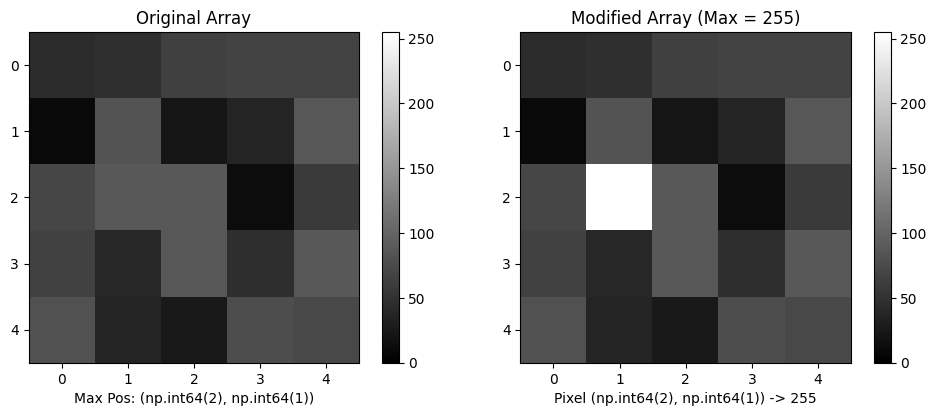

In [4]:
# 답안
import numpy as np
import matplotlib.pyplot as plt

# 1. 배열 생성 및 최댓값 위치 계산 (문제 1, 2와 동일 조건)
np.random.seed(0)
arr = np.random.randint(0, 100, size=(5, 5))

# 최댓값 위치 (행, 열) 구하기
max_idx = np.unravel_index(np.argmax(arr), arr.shape)

# 2. 원본 복사 후 최댓값 픽셀을 255로 변경
arr_modified = arr.copy()
arr_modified[max_idx] = 255

# 3. plt.subplots(1, 2)를 이용해 나란히 배치하여 시각화
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# 왼쪽: 원본 이미지
im1 = axes[0].imshow(arr, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Array")
axes[0].set_xlabel(f"Max Pos: {max_idx}")
plt.colorbar(im1, ax=axes[0])

# 오른쪽: 최댓값이 255로 변경된 이미지
im2 = axes[1].imshow(arr_modified, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Modified Array (Max = 255)")
axes[1].set_xlabel(f"Pixel {max_idx} -> 255")
plt.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.show()

## 문제 4. 오류 고치기 (20점)
아래 셀에는 오류가 있습니다. 실행해 메시지를 읽고 고친 뒤, **어떤 오류였고 shape이 어떻게 어긋났는지** 주석으로 적으세요.


In [5]:
p = np.arange(12).reshape(3, 4)
q = np.arange(12).reshape(3, 4)

print(p @ q)
# =========================================================================
# [발생한 오류]
# ValueError: shapes (3,4) and (3,4) not aligned: 4 (dim 1) != 3 (dim 0)
#
# [오류 원인 및 Shape 부합 문제]
# 행렬곱연산(p @ q)이 성립하려면 첫 번째 행렬의 열 개수(p의 dim 1)와
# 두 번째 행렬의 행 개수(q의 dim 0)가 서로 일치해야 합니다.
#
# 기존 p의 shape은 (3, 4)이고 q의 shape도 (3, 4)이므로,
# p의 열 개수(4)와 q의 행 개수(3)가 일치하지 않아(4 != 3) 오류가 발생했습니다.
# =========================================================================

# [수정 방법 1] q를 전치(Transpose)하여 shape을 (4, 3)으로 변환 후 행렬곱
# (3, 4) @ (4, 3) -> 결과 shape: (3, 3)
print("1. q를 전치(q.T)하여 행렬곱한 결과:")
print(p @ q.T)

print("\n" + "-"*40 + "\n")

# [수정 방법 2] q의 초기 reshape 크기를 (4, 3)으로 변경 후 행렬곱
q_fixed = np.arange(12).reshape(4, 3)
print("2. q의 shape을 (4, 3)으로 만들어서 행렬곱한 결과:")
print(p @ q_fixed)

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 3 is different from 4)